# ❄️ Energy Thermodynamics: Natural Gas Weather Freeze Spikes (FRED: 1997–Present)
## Polar Vortex Shocks, Pipeline Wellhead Freezes & Hurricane Supply Disruptions

### 1. Incident Background & Multi-Spike Commodity Physics
Natural gas is the primary fuel used for both **winter space heating** and **peaking electricity generation** across North America. Unlike oil (which can be stockpiled in tanks), natural gas is transported instantaneously via pressurized interstate pipeline networks with limited linepack storage.

When severe **polar vortex freezes** descend upon North America, two physical shocks collide simultaneously:
1. **Demand Explosion:** Residential heating furnaces and gas-fired power turbines fire at maximum capacity.
2. **Supply Collapse ("Freeze-Offs"):** Water vapor produced alongside raw methane freezes inside wellheads and gathering lines, physically choking off supply.

Across this 28-year benchmark from the Federal Reserve Bank of St. Louis (FRED `DHHNGSP`, covering 1997 to Present), the **Henry Hub Spot Price ($/MMBtu)** idles at a peaceful baseline of **$2.00 to $3.50 / MMBtu**, but experiences violent **+500% to +1,000% vertical price spikes** during extreme weather shocks:
* **February 2003 Polar Freeze:** Spiked to **$18.48 / MMBtu**.
* **September–December 2005 (Hurricanes Katrina & Rita):** Offshore Gulf production knocked offline; prices spiked to **$14.84 / MMBtu**.
* **January–February 2014 "Polar Vortex":** Arctic air paralyzed the Midwest; regional prices topped $100/MMBtu.
* **February 2021 Winter Storm Uri:** Historic deep freeze crippled Texas and Midcontinent grids; Henry Hub surged to **$23.86 / MMBtu** (and regional cash hubs traded over **$1,000 / MMBtu**).
* **January 2026 Arctic Blast:** Historic Arctic front pushing spot Henry Hub to **$30.72 / MMBtu**.

### 2. Target Variables ($y$)
* **`DHHNGSP`**: Henry Hub Natural Gas Spot Price ($/Million Btu).
* **`price_change_1d`**: Daily velocity ($\Delta y = y_t - y_{t-1}$).
* **`surge_multiplier`**: Daily price relative to the 365-day rolling median baseline.

### 3. Data Source
* Federal Reserve Bank of St. Louis (**FRED**) REST CSV Service (`DHHNGSP`).
* 100% public, free, zero API keys required.


### 📚 Academic Citations & Benchmark Lineage
* **Extreme Weather Energy Failure Report:** Federal Energy Regulatory Commission (FERC) & North American Electric Reliability Corporation (NERC). (2021). *"The February 2021 Cold Weather Outages in Texas and the South Central United States."* Joint Technical Staff Report.
* **Data Series:** Federal Reserve Bank of St. Louis, Henry Hub Natural Gas Spot Price (`DHHNGSP`).
* **BibTeX Citation:**
```bibtex
@techreport{ferc2021uri,
  title={The February 2021 Cold Weather Outages in Texas and the South Central United States},
  author={{Federal Energy Regulatory Commission} and {North American Electric Reliability Corporation}},
  institution={FERC-NERC},
  year={2021}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_henry_hub_prices(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'henry_hub_natural_gas_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached Henry Hub telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
    else:
        print("Fetching Henry Hub daily spot prices directly from FRED...")
        url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DHHNGSP'
        df = pd.read_csv(url)
        df.to_csv(cache_path, index=False)
        print(f"Downloaded and cached {len(df):,} daily spot price records.")
        
    date_col = 'observation_date' if 'observation_date' in df.columns else 'DATE'
    df = df.rename(columns={date_col: 'DATE'})
    df['DATE'] = pd.to_datetime(df['DATE'])
    df['price'] = pd.to_numeric(df['DHHNGSP'], errors='coerce')
    df = df.dropna(subset=['price']).sort_values('DATE').reset_index(drop=True)
    return df

df_gas = fetch_henry_hub_prices()
df_gas.head()

Fetching Henry Hub daily spot prices directly from FRED...


Downloaded and cached 7,771 daily spot price records.


,DATE,DHHNGSP,price
0,1997-01-07,3.82,3.82
1,1997-01-08,3.80,3.80
2,1997-01-09,3.61,3.61
3,1997-01-10,3.92,3.92
4,1997-01-13,4.00,4.00


### 5. Freeze Shock Feature Engineering & Spike Segmentation

In [3]:
df_gas_proc = df_gas.copy().sort_values('DATE').reset_index(drop=True)

# 1. Daily dollar change and percentage return
df_gas_proc['price_change_1d'] = df_gas_proc['price'].diff()
df_gas_proc['return_pct'] = df_gas_proc['price'].pct_change() * 100.0

# 2. 365-day rolling median baseline
df_gas_proc['baseline_365d_median'] = df_gas_proc['price'].rolling(365, min_periods=60).median()

# 3. Surge Multiplier relative to baseline
df_gas_proc['surge_multiplier'] = df_gas_proc['price'] / df_gas_proc['baseline_365d_median']

# 4. Rolling 1-year Z-Score
roll_mean_1y = df_gas_proc['price'].rolling(252, min_periods=40).mean()
roll_std_1y = df_gas_proc['price'].rolling(252, min_periods=40).std()
df_gas_proc['price_zscore_1y'] = (df_gas_proc['price'] - roll_mean_1y) / roll_std_1y

# 5. Automated Peak Detection of Weather Shock Spikes (price >= $12, distance >= 60 days)
peaks, _ = find_peaks(df_gas_proc['price'].values, height=12.0, distance=60, prominence=5.0)
df_gas_proc['is_freeze_spike'] = 0
df_gas_proc.loc[peaks, 'is_freeze_spike'] = 1

print(f"Total Trading Sessions Analyzed:         {len(df_gas_proc):,}")
print(f"Historical Median Spot Price:             USD {df_gas_proc['price'].median():.2f} / MMBtu")
print(f"Detected Severe Freeze/Storm Spikes:      {len(peaks)} major episodes")
print(f"All-Time Record Spot Price:               USD {df_gas_proc['price'].max():.2f} / MMBtu on {df_gas_proc.loc[df_gas_proc['price'].idxmax(), 'DATE'].strftime('%Y-%m-%d')}")
print(f"Max Single-Day Surge:                     +USD {df_gas_proc['price_change_1d'].max():.2f} (+{df_gas_proc['return_pct'].max():.1f}%)")
print(f"Peak Surge Multiplier vs Baseline:        {df_gas_proc['surge_multiplier'].max():.1f}x normal price")
df_gas_proc.head()

Total Trading Sessions Analyzed:         5,712
Historical Median Spot Price:             USD 3.20 / MMBtu
Detected Severe Freeze/Storm Spikes:      6 major episodes
All-Time Record Spot Price:               USD 30.72 / MMBtu on 2026-01-23
Max Single-Day Surge:                     +USD 22.30 (+319.0%)
Peak Surge Multiplier vs Baseline:        11.0x normal price


,DATE,DHHNGSP,price,price_change_1d,return_pct,baseline_365d_median,surge_multiplier,price_zscore_1y,is_freeze_spike
0,1997-01-07,3.82,3.82,NaN,NaN,NaN,NaN,NaN,0
1,1997-01-08,3.80,3.80,-0.02,-0.523560,NaN,NaN,NaN,0
2,1997-01-09,3.61,3.61,-0.19,-5.000000,NaN,NaN,NaN,0
3,1997-01-10,3.92,3.92,0.31,8.587258,NaN,NaN,NaN,0
4,1997-01-13,4.00,4.00,0.08,2.040816,NaN,NaN,NaN,0


### 6. Timeline Visualizations of 28 Years of Energy Freeze Spikes

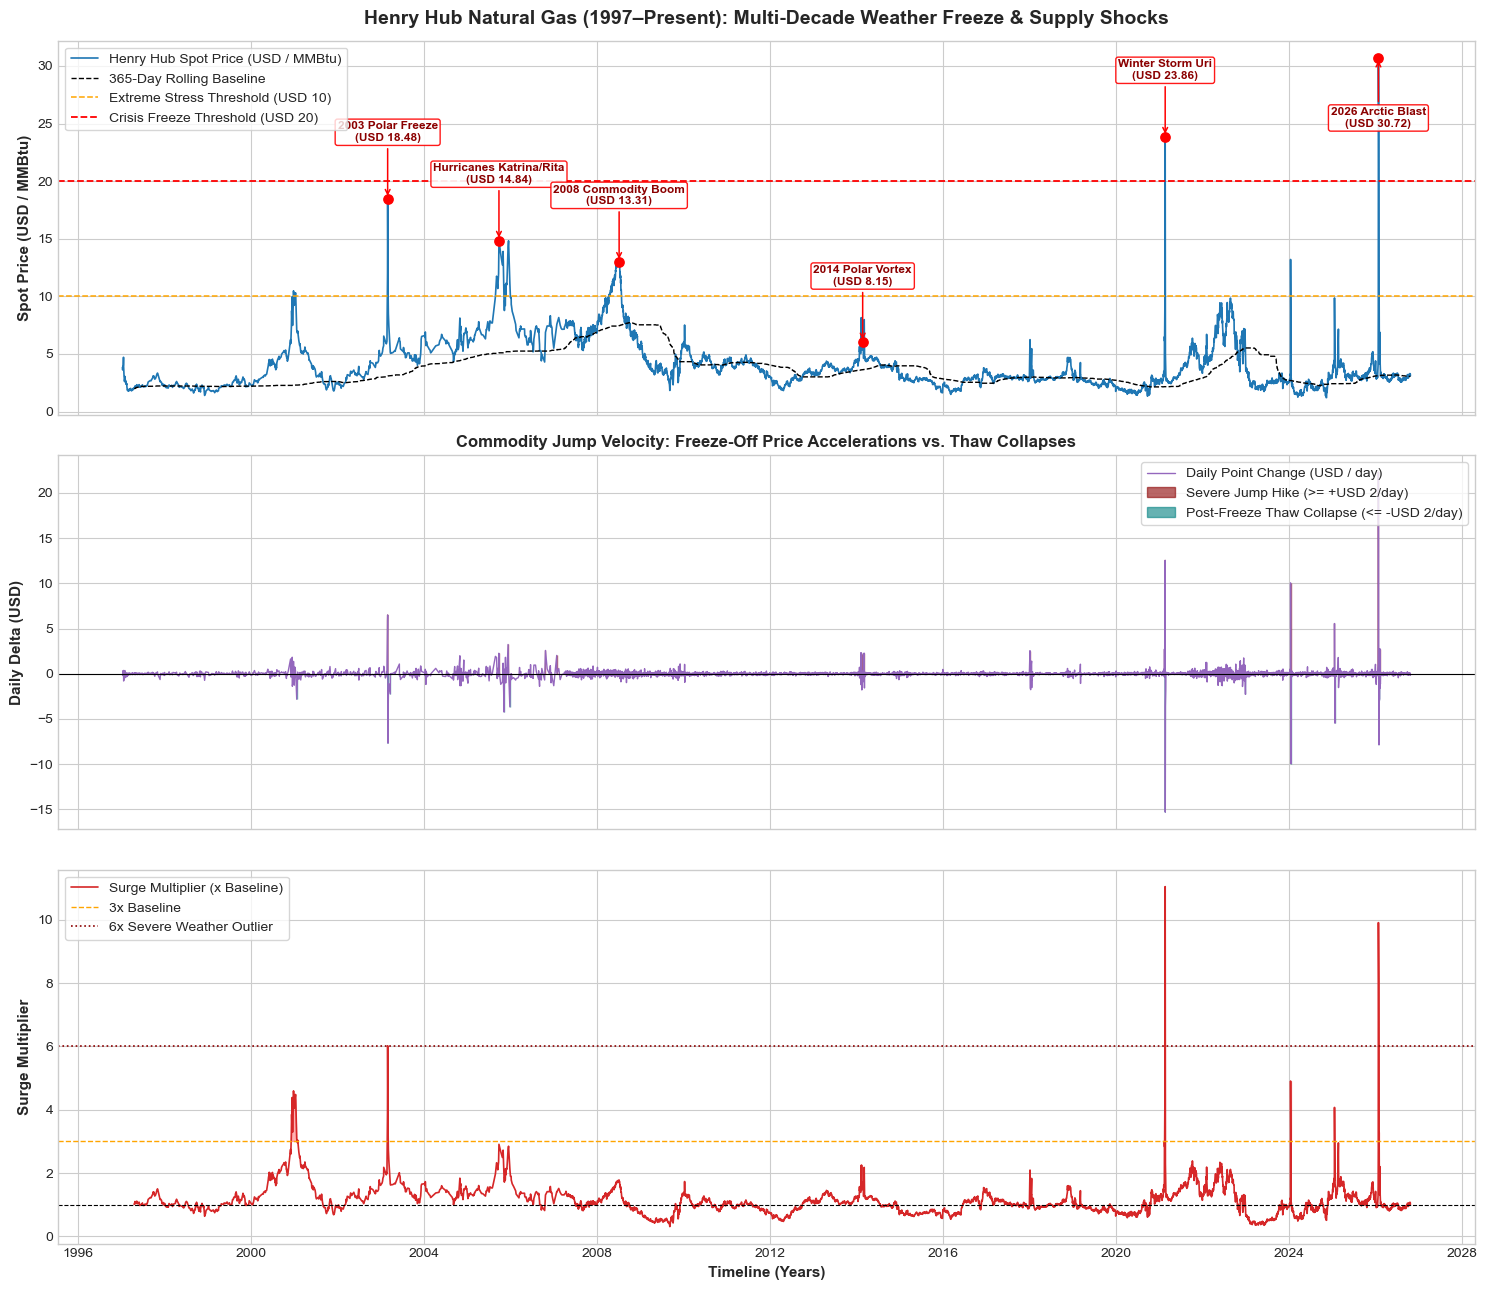

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. 28-Year Spot Price Timeline with Extreme Weather Annotations
ax1 = axes[0]
ax1.plot(df_gas_proc['DATE'], df_gas_proc['price'], color='#1f77b4', lw=1.2, label='Henry Hub Spot Price (USD / MMBtu)')
ax1.plot(df_gas_proc['DATE'], df_gas_proc['baseline_365d_median'], color='black', lw=1.0, ls='--', label='365-Day Rolling Baseline')
ax1.axhline(10.0, color='orange', ls='--', lw=1.1, label='Extreme Stress Threshold (USD 10)')
ax1.axhline(20.0, color='red', ls='--', lw=1.3, label='Crisis Freeze Threshold (USD 20)')

gas_events = [
    ('2003-02-25', '2003 Polar Freeze\n(USD 18.48)', 18.48),
    ('2005-09-22', 'Hurricanes Katrina/Rita\n(USD 14.84)', 14.84),
    ('2008-07-03', '2008 Commodity Boom\n(USD 13.31)', 13.31),
    ('2014-02-19', '2014 Polar Vortex\n(USD 8.15)', 8.15),
    ('2021-02-17', 'Winter Storm Uri\n(USD 23.86)', 23.86),
    ('2026-01-23', '2026 Arctic Blast\n(USD 30.72)', 30.72)
]

for date_str, label, y_val in gas_events:
    dt = pd.to_datetime(date_str)
    if dt in df_gas_proc['DATE'].values:
        actual = df_gas_proc.loc[df_gas_proc['DATE'] == dt, 'price'].values[0]
        ax1.scatter(dt, actual, color='red', s=45, zorder=5)
        offset_y = 5.0 if actual < 25 else -6.0
        ax1.annotate(label, xy=(dt, actual), xytext=(dt, actual + offset_y),
                     arrowprops=dict(arrowstyle="->", color='red', lw=1.1),
                     fontsize=8.5, fontweight='bold', color='#8b0000', ha='center',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor='red'))

ax1.set_title("Henry Hub Natural Gas (1997–Present): Multi-Decade Weather Freeze & Supply Shocks", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Spot Price (USD / MMBtu)", fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', frameon=True)

# 2. Daily Price Velocity (delta $/MMBtu / day)
ax2 = axes[1]
ax2.plot(df_gas_proc['DATE'], df_gas_proc['price_change_1d'], color='#9467bd', lw=1.0, label='Daily Point Change (USD / day)')
ax2.axhline(0, color='black', lw=0.8)
ax2.fill_between(df_gas_proc['DATE'], 0, df_gas_proc['price_change_1d'], 
                 where=(df_gas_proc['price_change_1d'] >= 2.0), color='darkred', alpha=0.6, label='Severe Jump Hike (>= +USD 2/day)')
ax2.fill_between(df_gas_proc['DATE'], 0, df_gas_proc['price_change_1d'], 
                 where=(df_gas_proc['price_change_1d'] <= -2.0), color='teal', alpha=0.6, label='Post-Freeze Thaw Collapse (<= -USD 2/day)')
ax2.set_ylabel("Daily Delta (USD)", fontsize=11, fontweight='bold')
ax2.set_title("Commodity Jump Velocity: Freeze-Off Price Accelerations vs. Thaw Collapses", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Surge Multiplier (Price / 365d Median)
ax3 = axes[2]
ax3.plot(df_gas_proc['DATE'], df_gas_proc['surge_multiplier'], color='#d62728', lw=1.2, label='Surge Multiplier (x Baseline)')
ax3.axhline(1.0, color='black', lw=0.8, ls='--')
ax3.axhline(3.0, color='orange', ls='--', lw=1.0, label='3x Baseline')
ax3.axhline(6.0, color='darkred', ls=':', lw=1.2, label='6x Severe Weather Outlier')
ax3.fill_between(df_gas_proc['DATE'], 3.0, df_gas_proc['surge_multiplier'], 
                 where=(df_gas_proc['surge_multiplier'] >= 3.0), color='red', alpha=0.3)
ax3.set_ylabel("Surge Multiplier", fontsize=11, fontweight='bold')
ax3.set_xlabel("Timeline (Years)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('data/henry_hub_freeze_timeline.png', dpi=300)
plt.show()

### 7. Historical Freeze Shock Ranking & Processed Export

In [5]:
# Summary table of top energy freeze spikes
freeze_df = df_gas_proc[df_gas_proc['is_freeze_spike'] == 1].sort_values('price', ascending=False).head(12)
freeze_table = freeze_df[['DATE', 'price', 'price_change_1d', 'surge_multiplier', 'price_zscore_1y']].copy()
freeze_table['DATE'] = freeze_table['DATE'].dt.strftime('%Y-%m-%d')
print("=== Top Historical Henry Hub Weather Freeze Spikes ===")
print(freeze_table.to_string(index=False))

# Export clean processed dataset
out_path = 'data/henry_hub_freeze_processed.csv'
df_gas_proc.to_csv(out_path, index=False)
print(f"\nProcessed natural gas dataset successfully saved to: {out_path}")

=== Top Historical Henry Hub Weather Freeze Spikes ===
      DATE  price  price_change_1d  surge_multiplier  price_zscore_1y
2026-01-23  30.72            22.30          9.909677        14.270280
2021-02-17  23.86            12.54         11.046296        13.466054
2003-02-25  18.48             6.50          6.019544         6.670558
2005-09-22  14.84             0.58          2.909804         4.026502
2008-07-02  13.31             0.03          1.786577         2.298266
2024-01-12  13.20            10.05          4.907063        14.031746

Processed natural gas dataset successfully saved to: data/henry_hub_freeze_processed.csv
